# Engineering borrower-level features
Relative amounts describe how large a loan or balance is for a particular borrower. This notebook calculates each feature row by row and uses the outcome only afterward for descriptive comparisons.

In [1]:
from pathlib import Path
import sys
import numpy as np
import pandas as pd
from IPython.display import Markdown, display

ROOT = Path.cwd()
if not (ROOT / "train.csv").exists():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))
train = pd.read_csv(ROOT / "train.csv")

import matplotlib.pyplot as plt
from src.feature_engineering import CreditFeatures, ENGINEERED

raw = train.drop(columns="default_flag")
# fit checks the input schema only. No encoder, imputer, or scaler is fitted here.
features = CreditFeatures().fit(raw.iloc[:1]).transform(raw)
display(features[ENGINEERED].describe(percentiles=[.25, .5, .75, .95, .99]).T)
display(features[ENGINEERED].isna().sum().rename("undefined"))

,count,mean,std,min,25%,50%,75%,95%,99%,max
loan_to_income,31016.0,0.186296,0.115349,0.000789,0.098594,0.163636,0.25000,0.411765,0.520000,0.830000
revolving_balance_to_income,31016.0,0.201757,0.187830,0.000000,0.068987,0.156057,0.28084,0.546412,0.836901,3.116475
has_prior_delinquency,31016.0,0.109008,0.311655,0.000000,0.000000,0.000000,0.00000,1.000000,1.000000,1.000000


loan_to_income                 0
revolving_balance_to_income    0
has_prior_delinquency          0
Name: undefined, dtype: int64

## Inspect the retained features
Loan-to-income measures requested principal relative to annual gross earnings. Revolving-balance-to-income measures outstanding revolving debt on the same scale. A binary flag distinguishes borrowers with any prior delinquency. Each is a different representation of information already present.

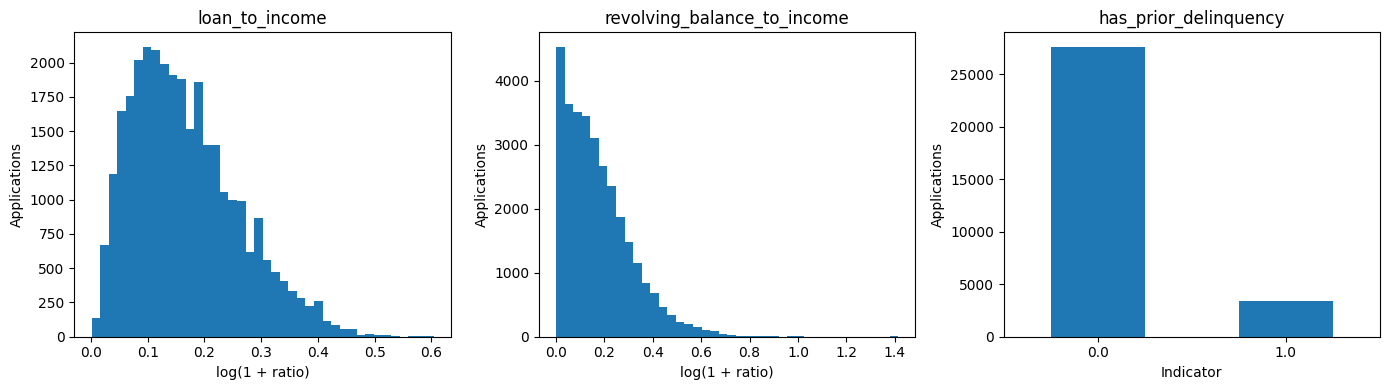

The median loan_to_income is 0.164, compared with 0.520 at the 99th percentile.

The median revolving_balance_to_income is 0.156, compared with 0.837 at the 99th percentile.

3,381 applications report a prior delinquency.

In [2]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for col, ax in zip(ENGINEERED, axes):
    if col == "has_prior_delinquency":
        features[col].value_counts().sort_index().plot.bar(ax=ax, rot=0)
    else:
        # Log1p allows zero while making the long tail readable.
        ax.hist(np.log1p(features[col].dropna()), bins=40)
    ax.set(title=col, xlabel="Indicator" if col == "has_prior_delinquency" else "log(1 + ratio)",
           ylabel="Applications")
fig.tight_layout()
fig.savefig(ROOT / "reports" / "figures" / "engineered_distributions.png", dpi=120)
plt.show()
for col in ENGINEERED[:2]:
    display(Markdown(f"The median {col} is {features[col].median():.3f}, compared with "
                     f"{features[col].quantile(.99):.3f} at the 99th percentile."))
display(Markdown(f"{features.has_prior_delinquency.sum():,.0f} applications report a prior delinquency."))

## Compare outcomes by feature value
Quintiles are descriptive bins computed here for the two ratios. The pipeline retains continuous ratios. Default percentages are historical group averages.

In [3]:
for col in ENGINEERED:
    group = features[col]
    if col != "has_prior_delinquency":
        group = pd.qcut(group, 5, duplicates="drop")
    table = train.default_flag.groupby(group, observed=True, dropna=False).agg(["size", "sum", "mean"])
    table.columns = ["applications", "defaults", "default_rate"]
    table["default_percent"] = table.pop("default_rate") * 100
    display(Markdown(f"**{col}**"), table.round(2))
    display(Markdown(f"The first and last observed groups have default rates of "
                     f"{table.default_percent.iloc[0]:.2f}% and {table.default_percent.iloc[-1]:.2f}%."))

**loan_to_income**

,applications,defaults,default_percent
loan_to_income,,,
"(-0.00021100000000000003, 0.0853]",6207,710,11.44
"(0.0853, 0.136]",6231,704,11.30
"(0.136, 0.194]",6172,780,12.64
"(0.194, 0.278]",6292,981,15.59
"(0.278, 0.83]",6114,1332,21.79


The first and last observed groups have default rates of 11.44% and 21.79%.

**revolving_balance_to_income**

,applications,defaults,default_percent
revolving_balance_to_income,,,
"(-0.001, 0.0528]",6204,742,11.96
"(0.0528, 0.12]",6203,813,13.11
"(0.12, 0.199]",6203,867,13.98
"(0.199, 0.319]",6203,984,15.86
"(0.319, 3.116]",6203,1101,17.75


The first and last observed groups have default rates of 11.96% and 17.75%.

**has_prior_delinquency**

,applications,defaults,default_percent
has_prior_delinquency,,,
0.0,27635,3942,14.26
1.0,3381,565,16.71


The first and last observed groups have default rates of 14.26% and 16.71%.

## Investigate alternative definitions
Monthly income is annual income divided by 12. EMI-to-income is the scheduled monthly payment divided by monthly income. These calculations illustrate contractual burden. The PDF does not establish submission-time availability of the EMI. Adding this ratio to DTI could also count the installment twice if DTI already includes it.

In [4]:
monthly_income = features.annual_income / 12
emi_share = raw.monthly_emi / monthly_income.where(monthly_income > 0)
display(pd.DataFrame({"monthly_income": monthly_income, "scheduled_emi_share": emi_share}).describe().T)
bands = pd.cut(features.revolving_utilization_pct, [-np.inf, 30, 70, np.inf],
               labels=["up to 30%", "over 30 to 70%", "over 70%"])
display(bands.value_counts(dropna=False).rename("applications"))

,count,mean,std,min,25%,50%,75%,max
monthly_income,31016.0,5741.435835,5598.349581,333.333333,3333.333333,4916.666667,6833.333333,500000.000000
scheduled_emi_share,31016.0,0.065684,0.039991,0.000289,0.035237,0.057909,0.088095,0.320262


revolving_utilization_pct
over 30 to 70%    13339
up to 30%          9184
over 70%           8455
NaN                  38
Name: applications, dtype: int64

Keep annual income and continuous utilization. Monthly income is an exact rescaling, and these illustrative utilization cutoffs discard within-band differences. The original DTI and the loan-to-income ratio describe debt pressure without requiring the scheduled payment. Credit-history duration is absent, so a balance-per-history-year feature cannot be calculated.